# 3. Tune and cross-validate
Tunes both forests and the decision thresholds on out-of-fold scores of the development data only, then freezes `outputs/final_config.json`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
from toadwatch import config as C, workflow as W, charts, report_builder
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160)
def show(*names):
    for n in names:
        display(Image(filename=str(C.FIGURES_DIR / n)))

In [2]:
r = W.load_cv_results() if C.FINAL_TEST_LOCK.exists() else W.tune_and_cv()
r['overall'][['accuracy', 'f1', 'balanced_accuracy']].round(4)

,accuracy,f1,balanced_accuracy
call_only,0.8135,0.7926,0.8137
message_only,0.7481,0.7535,0.7481
combined,0.9013,0.8995,0.9013


In [3]:
r['config']['thresholds'], r['config']['params']

({'call_only': 0.4, 'message_only': 0.25, 'combined': [0.55, 0.7]},
 {'call': {'n_estimators': 300,
   'max_depth': 12,
   'min_samples_leaf': 3,
   'max_features': 'sqrt'},
  'message': {'n_estimators': 300,
   'max_depth': 12,
   'min_samples_leaf': 1,
   'max_features': 'sqrt'}})

In [4]:
r['by_tier'].round(3)

,model,tier,n,accuracy,f1,balanced_accuracy,recall,false_alarm_rate
0,call_only,hard,426,0.641,0.588,0.642,0.507,0.223
1,call_only,matched,2508,0.849,0.837,0.849,0.774,0.076
2,call_only,unmatched,814,0.794,0.754,0.795,0.629,0.040
3,message_only,hard,426,0.709,0.743,0.708,0.833,0.417
4,message_only,matched,2508,0.752,0.755,0.752,0.764,0.259
5,message_only,unmatched,814,0.756,0.756,0.756,0.751,0.240
6,combined,hard,426,0.732,0.729,0.733,0.712,0.246
7,combined,matched,2508,0.935,0.935,0.935,0.931,0.061
8,combined,unmatched,814,0.885,0.878,0.885,0.822,0.052


In [5]:
r['by_pair_type'].round(3)

,model,pair_type,n,accuracy
0,call_only,FF,935,0.910
1,call_only,FS,471,0.934
2,call_only,SF,471,0.096
3,call_only,SS,1871,0.916
4,message_only,FF,935,0.936
5,message_only,FS,471,0.280
6,message_only,SF,471,0.926
7,message_only,SS,1871,0.727
8,combined,FF,935,0.955
9,combined,FS,471,0.913


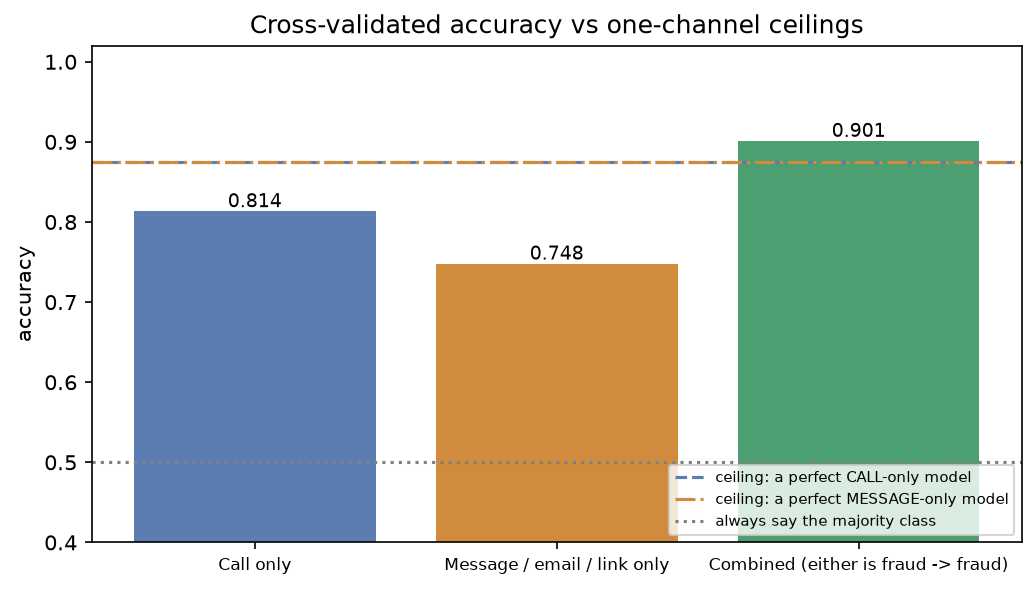

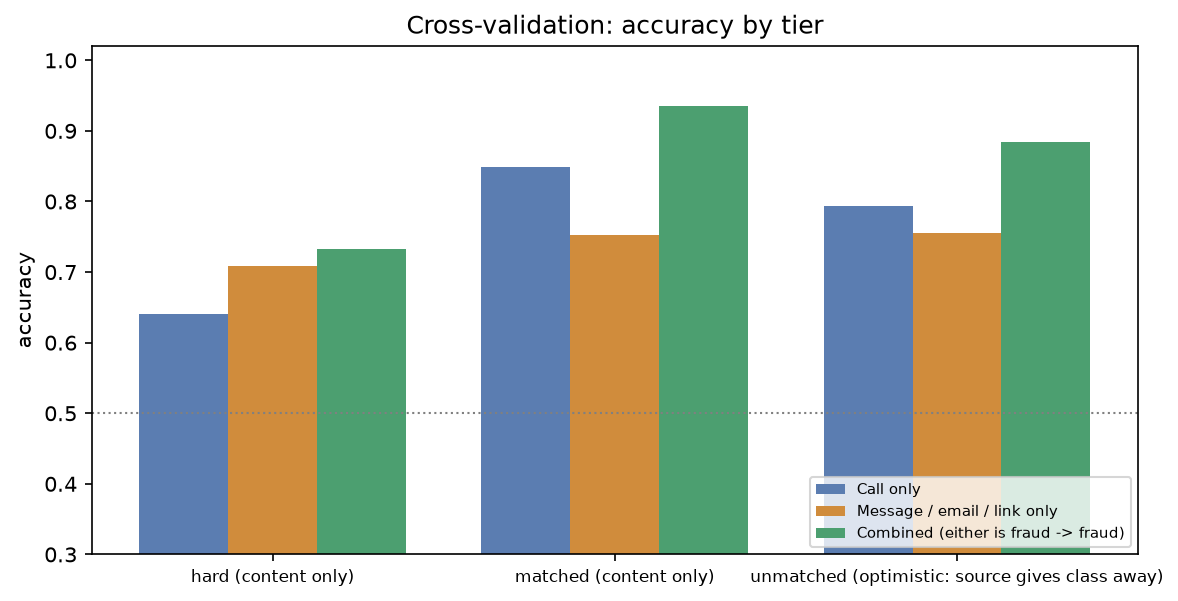

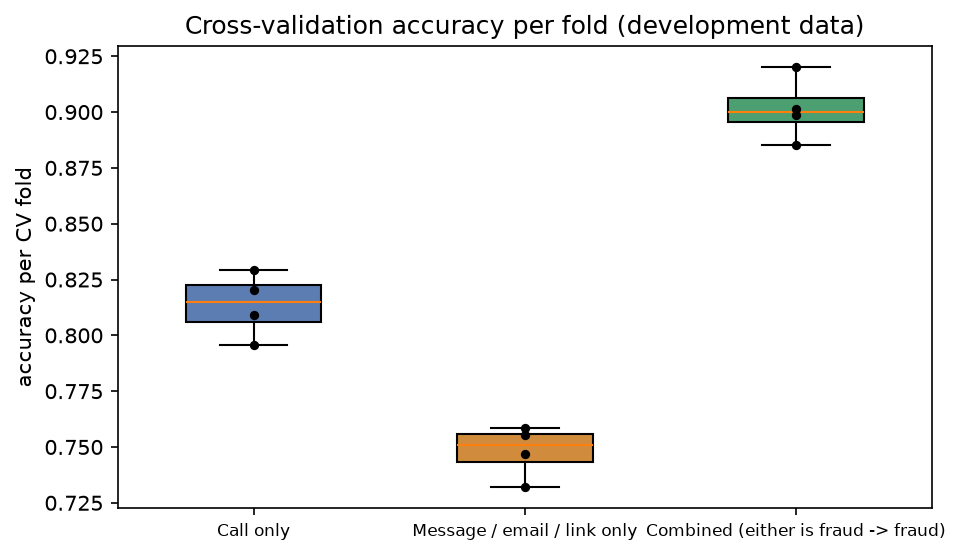

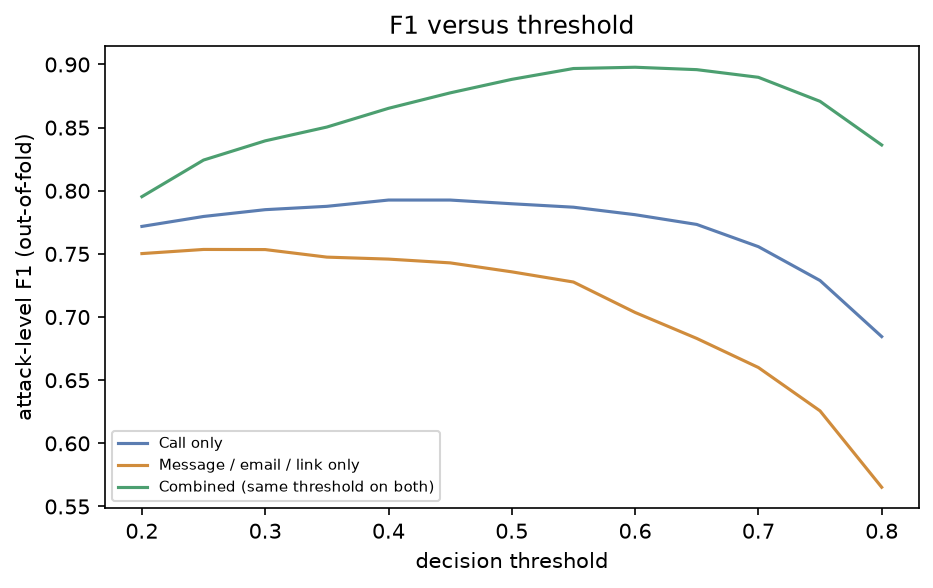

In [6]:
charts.make_all_charts(); show('01_cv_accuracy_vs_ceilings.png', '03_cv_tiers.png', '05_cv_boxplot.png', '10_threshold_sweep.png')